FinEdge FRAUD DETECTION EXPERIMENT

[1] Loading PaySim dataset...
Shape: (6362620, 11)
Fraud: 8213
Non-Fraud: 6354407
Fraud rate (%): 0.12908204481801522

Common features:
 - amount
 - oldbalanceOrg
 - newbalanceOrig
 - oldbalanceDest
 - newbalanceDest
 - type_CASH_IN
 - type_CASH_OUT
 - type_DEBIT
 - type_PAYMENT
 - type_TRANSFER

Feature count: 10

[2] Creating common 70/15/15 stratified split...

TRAIN
Samples: 4453834
Fraud: 5749
Fraud rate: 0.001290797995614565

VALIDATION
Samples: 954393
Fraud: 1232
Fraud rate: 0.001290872837499856

TEST
Samples: 954393
Fraud: 1232
Fraud rate: 0.001290872837499856

Validation subdivision:
META      : (477196, 10) Fraud = 616
THRESHOLD : (477197, 10) Fraud = 616

BASELINE 1: RUS + XGBOOST
Fitting 5 folds for each of 9 candidates, totalling 45 fits
[CV] END .....model__max_depth=3, rus__sampling_strategy=0.5; total time=   2.8s
[CV] END .....model__max_depth=3, rus__sampling_strategy=0.5; total time=   3.0s
[CV] END .....model__max_depth=3, rus__sa

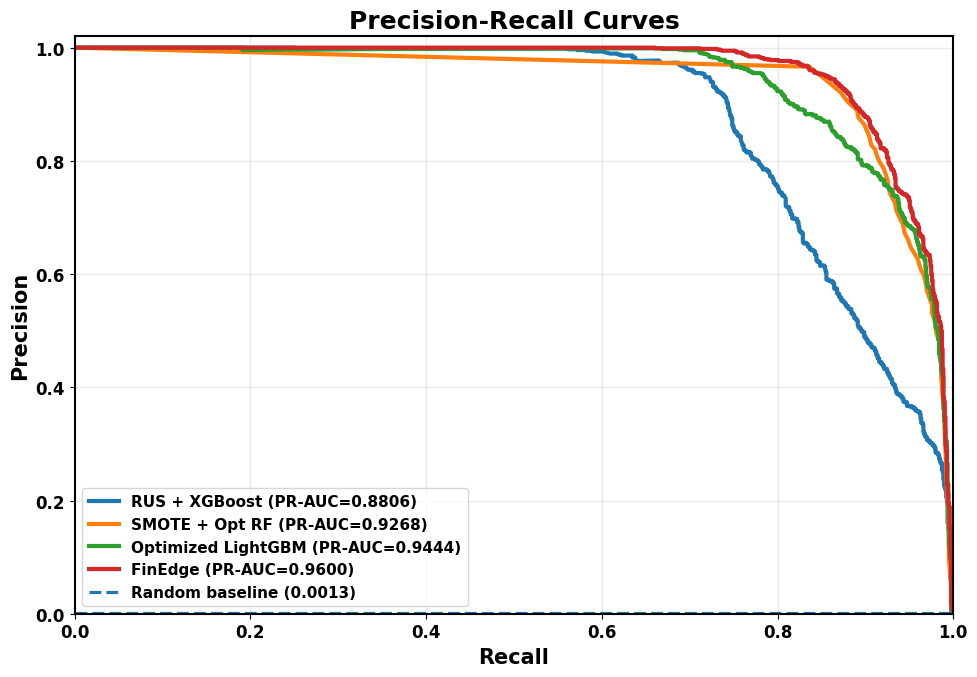

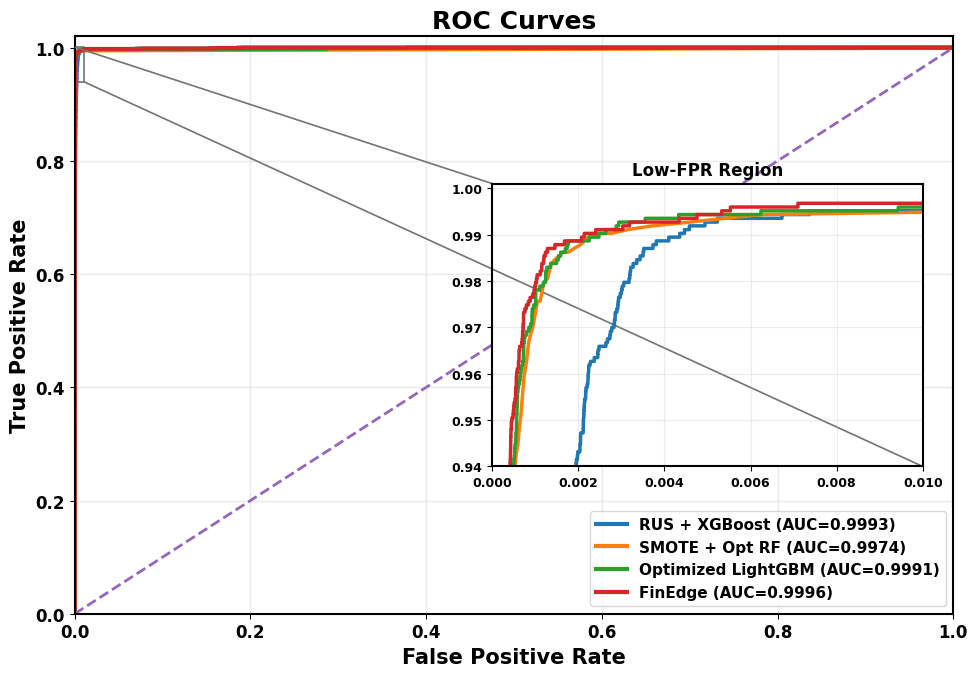

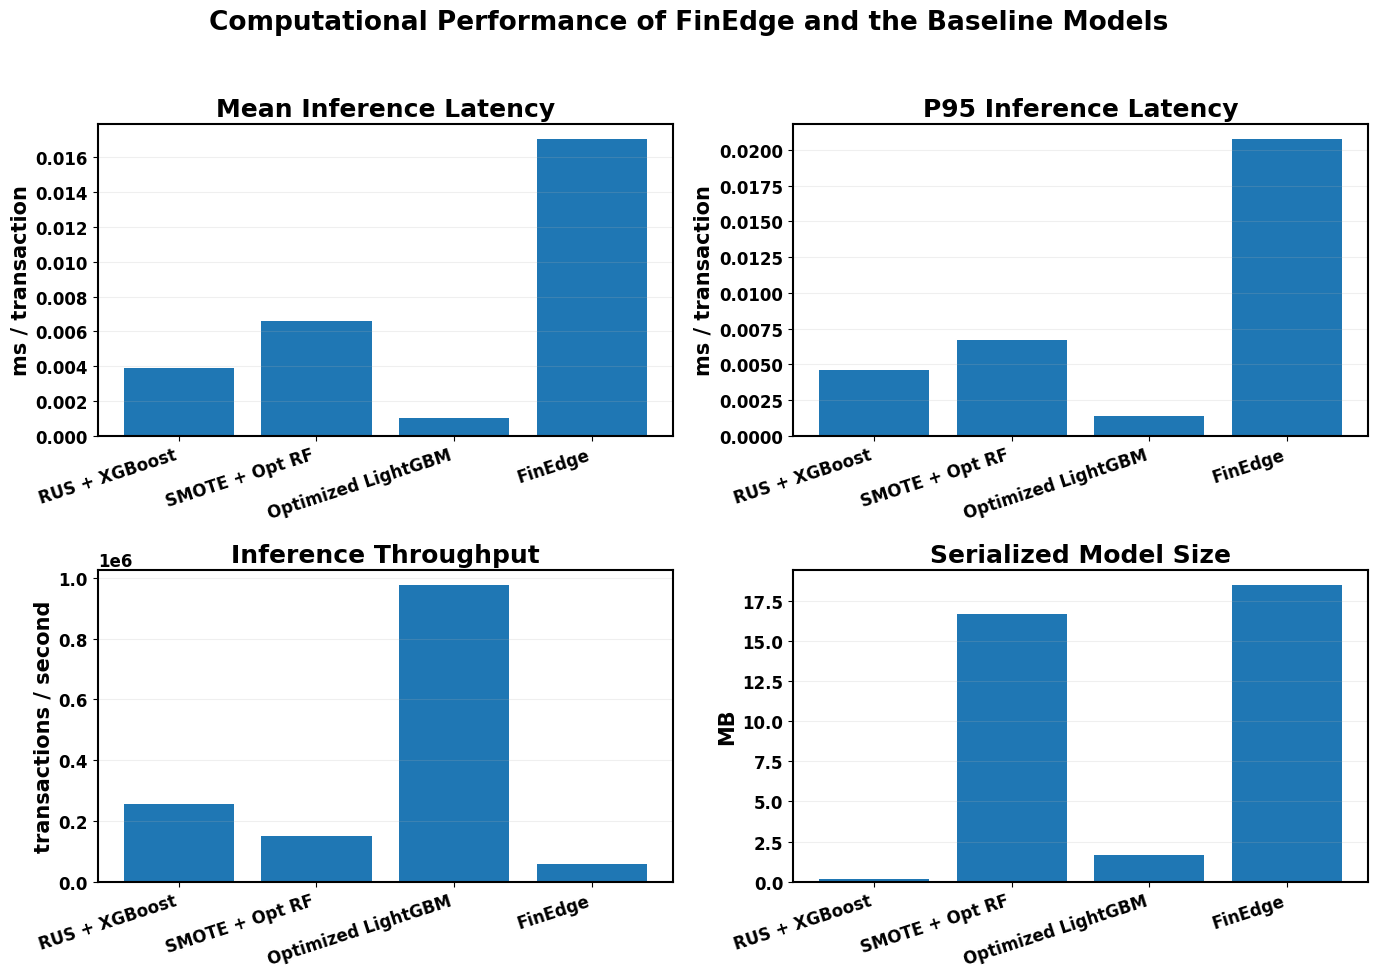

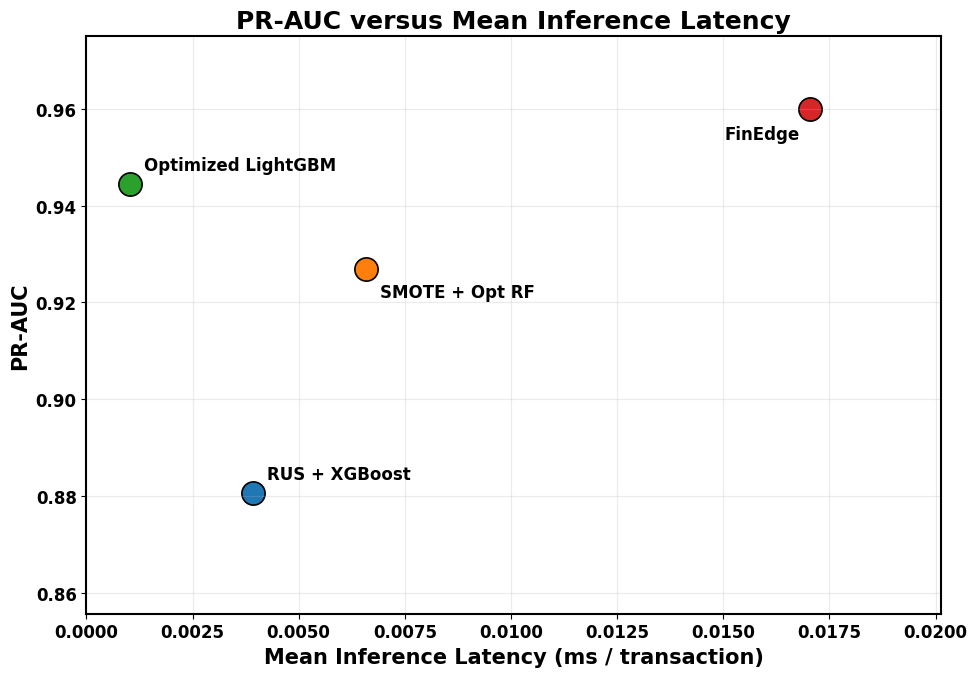

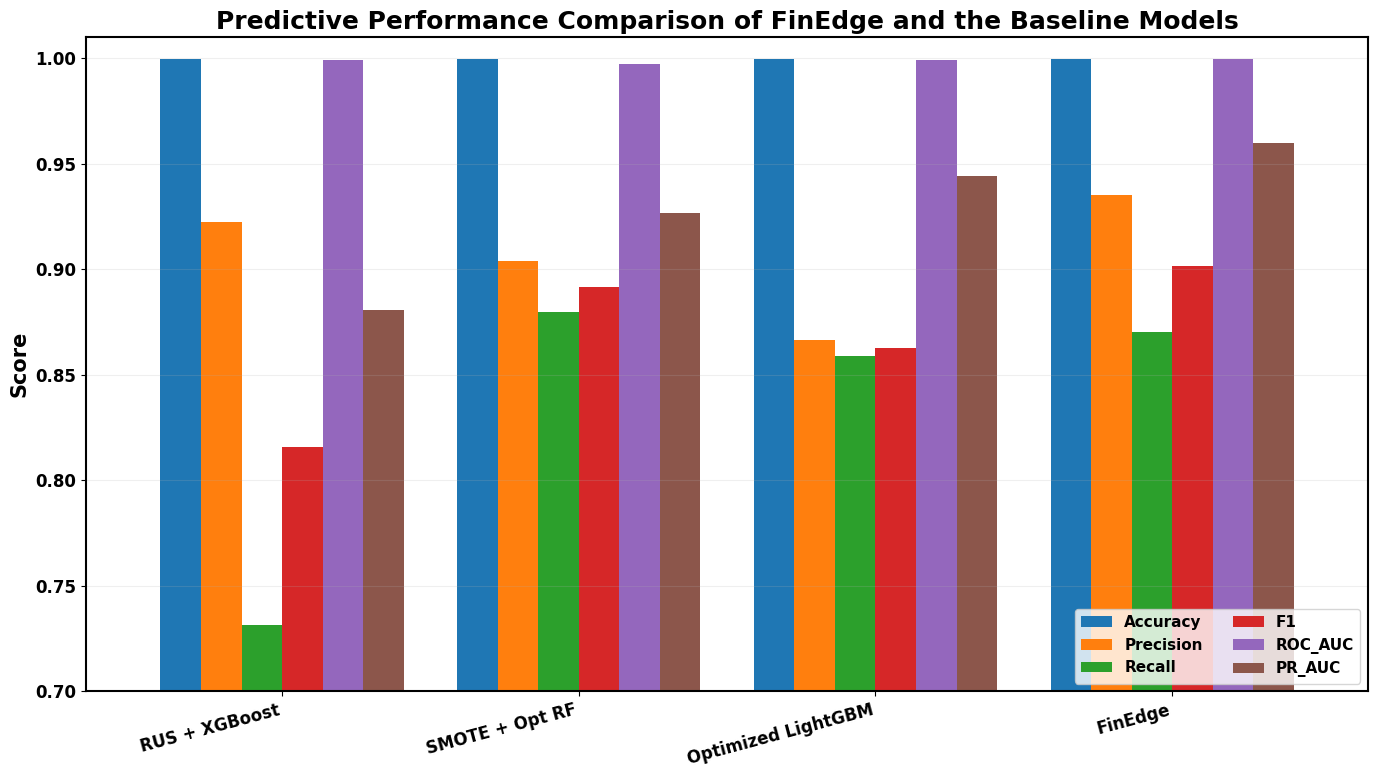



FinEdge EXPERIMENT COMPLETED

Results folder:
fraud_experiment_results

Figures folder:
fraud_experiment_results/figures

Models folder:
fraud_experiment_results/models

Generated figures:
1. precision_recall_curves.png
2. roc_curves_zoomed.png
3. computational_performance_comparison.png
4. prauc_vs_latency.png
5. predictive_performance_comparison.png

Generated tables:
1. predictive_performance_table.csv
2. computational_performance_table.csv


FINAL RESULTS
             Model  Accuracy  Precision   Recall       F1  ROC_AUC   PR_AUC  Mean_Latency_ms  P95_Latency_ms  Throughput_tx_per_sec  Model_Size_MB
     RUS + XGBoost  0.999574   0.922211 0.731331 0.815754 0.999325 0.880639         0.003915        0.004627          255402.691482       0.143146
    SMOTE + Opt RF  0.999724   0.904087 0.879870 0.891814 0.997425 0.926784         0.006581        0.006685          151956.989948      16.653799
Optimized LightGBM  0.999647   0.866503 0.858766 0.862617 0.999102 0.944430         0.001024 

In [1]:
# ================================================================
# FinEdge: A Resource-Aware Stacking Ensemble
# for Financial Fraud Detection on Edge Devices
#
# Baseline 1 : RUS + XGBoost
# Baseline 2 : SMOTE + Optimized Random Forest
# Baseline 3 : Bayesian-Optimized LightGBM
# FinEdge    : Probability-based Stacking Ensemble
#
# FINAL OUTPUTS
# ------------------------------------------------
# TABLES:
# 1) Predictive Performance Comparison
# 2) Computational Performance Comparison
#
# FIGURES:
# 1) Precision-Recall Curves
# 2) ROC Curves + Low-FPR Zoom
# 3) Computational Performance Comparison
# 4) PR-AUC vs Mean Inference Latency
# 5) Predictive Performance Comparison
#
# ALL FIGURES: 300 DPI
# ================================================================


# ================================================================
# 0. IMPORTS
# ================================================================

import os
import gc
import time
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

warnings.filterwarnings("ignore")


# ================================================================
# MACHINE LEARNING IMPORTS
# ================================================================

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    confusion_matrix
)

from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

import optuna


# ================================================================
# 1. GLOBAL SETTINGS
# ================================================================

RANDOM_STATE = 42

FILE_PATH = "/teamspace/studios/this_studio/paysim dataset.csv"

OUTPUT_DIR = "fraud_experiment_results"
MODEL_DIR = os.path.join(OUTPUT_DIR, "models")
FIGURE_DIR = os.path.join(OUTPUT_DIR, "figures")

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)


# ------------------------------------------------
# Optimization settings
# ------------------------------------------------

N_LGBM_TRIALS = 30
LGBM_TUNING_SIZE = 500_000
RF_TUNING_NORMAL = 500_000


# ------------------------------------------------
# Inference benchmark settings
# ------------------------------------------------

LATENCY_SAMPLES = 5000
LATENCY_REPEATS = 5
WARMUP_SAMPLES = 500


# ================================================================
# GLOBAL FIGURE STYLE
# ================================================================

plt.rcParams.update({

    "font.size": 14,
    "font.weight": "bold",

    "axes.labelweight": "bold",
    "axes.titleweight": "bold",

    "axes.titlesize": 18,
    "axes.labelsize": 15,

    "xtick.labelsize": 12,
    "ytick.labelsize": 12,

    "legend.fontsize": 11,

    "figure.titlesize": 18,

    "axes.linewidth": 1.5,

    "savefig.dpi": 300
})


print("=" * 90)
print("FinEdge FRAUD DETECTION EXPERIMENT")
print("=" * 90)


# ================================================================
# 2. LOAD PAYSim
# ================================================================

print("\n[1] Loading PaySim dataset...")

df = pd.read_csv(FILE_PATH)

print("Shape:", df.shape)
print("Fraud:", int(df["isFraud"].sum()))
print("Non-Fraud:", int((df["isFraud"] == 0).sum()))
print("Fraud rate (%):", df["isFraud"].mean() * 100)


# ================================================================
# 3. COMMON FEATURE SET
# ================================================================

y = df["isFraud"].astype(np.uint8)

X = df[
    [
        "type",
        "amount",
        "oldbalanceOrg",
        "newbalanceOrig",
        "oldbalanceDest",
        "newbalanceDest"
    ]
].copy()


# ------------------------------------------------
# One-hot encoding
# ------------------------------------------------

X = pd.get_dummies(

    X,

    columns=["type"],

    prefix="type",

    dtype=np.uint8
)


print("\nCommon features:")

for col in X.columns:
    print(" -", col)

print("\nFeature count:", X.shape[1])


del df
gc.collect()


# ================================================================
# 4. COMMON TRAIN / VALIDATION / TEST SPLIT
#
# 70% Train
# 15% Validation
# 15% Test
# ================================================================

print("\n[2] Creating common 70/15/15 stratified split...")


X_train, X_temp, y_train, y_temp = train_test_split(

    X,
    y,

    test_size=0.30,

    random_state=RANDOM_STATE,

    stratify=y
)


X_val, X_test, y_val, y_test = train_test_split(

    X_temp,
    y_temp,

    test_size=0.50,

    random_state=RANDOM_STATE,

    stratify=y_temp
)


del X, y, X_temp, y_temp
gc.collect()


print("\nTRAIN")
print("Samples:", len(y_train))
print("Fraud:", int(y_train.sum()))
print("Fraud rate:", y_train.mean())


print("\nVALIDATION")
print("Samples:", len(y_val))
print("Fraud:", int(y_val.sum()))
print("Fraud rate:", y_val.mean())


print("\nTEST")
print("Samples:", len(y_test))
print("Fraud:", int(y_test.sum()))
print("Fraud rate:", y_test.mean())


# ================================================================
# 5. SPLIT VALIDATION SET
#
# Meta set:
#    Used to train FinEdge meta-classifier
#
# Threshold set:
#    Used to optimize classification thresholds
# ================================================================

X_meta, X_threshold, y_meta, y_threshold = train_test_split(

    X_val,
    y_val,

    test_size=0.50,

    random_state=RANDOM_STATE,

    stratify=y_val
)


print("\nValidation subdivision:")

print(
    "META      :",
    X_meta.shape,
    "Fraud =",
    int(y_meta.sum())
)

print(
    "THRESHOLD :",
    X_threshold.shape,
    "Fraud =",
    int(y_threshold.sum())
)


# ================================================================
# 6. UTILITY FUNCTIONS
# ================================================================


def find_best_threshold(y_true, probabilities):

    precision, recall, thresholds = precision_recall_curve(
        y_true,
        probabilities
    )

    precision = precision[:-1]
    recall = recall[:-1]

    f1 = (

        2 * precision * recall /

        (
            precision +
            recall +
            1e-15
        )
    )

    idx = np.nanargmax(f1)

    return (

        float(thresholds[idx]),

        float(f1[idx]),

        float(precision[idx]),

        float(recall[idx])
    )


# ------------------------------------------------


def evaluate_model(

    name,
    y_true,
    probabilities,
    threshold
):

    predictions = (

        probabilities >= threshold

    ).astype(np.uint8)


    tn, fp, fn, tp = confusion_matrix(

        y_true,
        predictions

    ).ravel()


    result = {

        "Model":
            name,

        "Threshold":
            threshold,

        "Accuracy":
            accuracy_score(
                y_true,
                predictions
            ),

        "Precision":
            precision_score(
                y_true,
                predictions,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_true,
                predictions
            ),

        "F1":
            f1_score(
                y_true,
                predictions
            ),

        "ROC_AUC":
            roc_auc_score(
                y_true,
                probabilities
            ),

        "PR_AUC":
            average_precision_score(
                y_true,
                probabilities
            ),

        "TP":
            tp,

        "FP":
            fp,

        "TN":
            tn,

        "FN":
            fn
    }


    return result, predictions


# ------------------------------------------------


def make_tuning_subset(

    X,
    y,
    normal_limit,
    random_state=42
):

    fraud_idx = y[
        y == 1
    ].index


    normal_idx = y[
        y == 0
    ].index


    rng = np.random.RandomState(
        random_state
    )


    n_normal = min(

        normal_limit,

        len(normal_idx)
    )


    selected_normal = rng.choice(

        normal_idx,

        size=n_normal,

        replace=False
    )


    selected_idx = np.concatenate([

        fraud_idx.to_numpy(),

        selected_normal
    ])


    rng.shuffle(
        selected_idx
    )


    return (

        X.loc[selected_idx],

        y.loc[selected_idx]
    )


# ------------------------------------------------


def benchmark_latency(

    model,
    X_sample,
    repeats=5,
    warmup=500
):

    X_sample = X_sample.reset_index(
        drop=True
    )


    warmup_n = min(

        warmup,

        len(X_sample)
    )


    # Warm-up
    _ = model.predict_proba(

        X_sample.iloc[
            :warmup_n
        ]
    )


    per_sample_latencies = []


    for _ in range(repeats):

        start = time.perf_counter()

        _ = model.predict_proba(
            X_sample
        )

        elapsed = (
            time.perf_counter()
            -
            start
        )


        latency_ms = (

            elapsed /

            len(X_sample)

            * 1000
        )


        per_sample_latencies.append(
            latency_ms
        )


    arr = np.asarray(
        per_sample_latencies
    )


    mean_ms = np.mean(arr)

    median_ms = np.median(arr)

    p95_ms = np.percentile(
        arr,
        95
    )

    throughput = (
        1000 /
        mean_ms
    )


    return (

        mean_ms,
        median_ms,
        p95_ms,
        throughput
    )


# ------------------------------------------------


def get_model_size_mb(

    model,
    filename
):

    path = os.path.join(

        MODEL_DIR,

        filename
    )


    joblib.dump(

        model,

        path,

        compress=3
    )


    size_mb = (

        os.path.getsize(path)

        /
        1024**2
    )


    return size_mb


# ================================================================
# 7. BASELINE 1
# RUS + XGBOOST
# ================================================================

print("\n" + "=" * 90)
print("BASELINE 1: RUS + XGBOOST")
print("=" * 90)


rus_xgb_pipeline = Pipeline([

    (

        "rus",

        RandomUnderSampler(

            random_state=
            RANDOM_STATE
        )
    ),

    (

        "model",

        XGBClassifier(

            objective=
                "binary:logistic",

            eval_metric=
                "logloss",

            booster=
                "gbtree",

            learning_rate=
                0.3,

            gamma=
                0,

            reg_lambda=
                1,

            reg_alpha=
                0,

            subsample=
                1.0,

            random_state=
                RANDOM_STATE,

            n_estimators=
                100,

            n_jobs=
                -1
        )
    )
])


rus_xgb_grid = {

    "rus__sampling_strategy":
        [
            0.5,
            0.75,
            1.0
        ],

    "model__max_depth":
        [
            3,
            6,
            9
        ]
}


cv5 = StratifiedKFold(

    n_splits=5,

    shuffle=True,

    random_state=
        RANDOM_STATE
)


rus_xgb_search = GridSearchCV(

    estimator=
        rus_xgb_pipeline,

    param_grid=
        rus_xgb_grid,

    scoring=
        "f1",

    cv=
        cv5,

    n_jobs=
        -1,

    verbose=
        2
)


rus_xgb_search.fit(

    X_train,
    y_train
)


model_xgb = (
    rus_xgb_search.best_estimator_
)


print(
    "\nBest RUS + XGBoost parameters:"
)

print(
    rus_xgb_search.best_params_
)

print(
    "CV F1:",
    rus_xgb_search.best_score_
)


# ================================================================
# 8. BASELINE 2
# SMOTE + OPTIMIZED RANDOM FOREST
# ================================================================

print("\n" + "=" * 90)
print("BASELINE 2: SMOTE + OPTIMIZED RANDOM FOREST")
print("=" * 90)


X_rf_tune, y_rf_tune = make_tuning_subset(

    X_train,

    y_train,

    RF_TUNING_NORMAL,

    RANDOM_STATE
)


print(
    "RF tuning subset:",
    X_rf_tune.shape
)

print(
    "Fraud:",
    int(y_rf_tune.sum())
)


smote_rf_pipeline = Pipeline([

    (

        "smote",

        SMOTE(

            sampling_strategy=
                1.0,

            random_state=
                RANDOM_STATE,

            k_neighbors=
                5
        )
    ),

    (

        "model",

        RandomForestClassifier(

            random_state=
                RANDOM_STATE,

            n_jobs=
                -1,

            max_features=
                "sqrt",

            min_samples_split=
                2,

            class_weight=
                "balanced"
        )
    )
])


rf_grid = {

    "model__n_estimators":
        [
            50,
            100
        ],

    "model__max_depth":
        [
            None,
            10
        ],

    "model__min_samples_leaf":
        [
            1,
            2
        ]
}


rf_search = GridSearchCV(

    estimator=
        smote_rf_pipeline,

    param_grid=
        rf_grid,

    scoring=
        "f1",

    cv=
        3,

    n_jobs=
        -1,

    verbose=
        2
)


rf_search.fit(

    X_rf_tune,

    y_rf_tune
)


print(
    "\nBest RF parameters:"
)

print(
    rf_search.best_params_
)

print(
    "CV F1:",
    rf_search.best_score_
)


best_rf_params = (
    rf_search.best_params_
)


del (
    X_rf_tune,
    y_rf_tune,
    rf_search
)

gc.collect()


# ================================================================
# FULL SMOTE TRAINING
# ================================================================

print(
    "\nApplying SMOTE to full training set..."
)


smote = SMOTE(

    sampling_strategy=
        1.0,

    random_state=
        RANDOM_STATE,

    k_neighbors=
        5
)


X_train_smote, y_train_smote = (

    smote.fit_resample(

        X_train,

        y_train
    )
)


print(
    "SMOTE training shape:",
    X_train_smote.shape
)


model_rf = RandomForestClassifier(

    n_estimators=
        best_rf_params[
            "model__n_estimators"
        ],

    max_depth=
        best_rf_params[
            "model__max_depth"
        ],

    min_samples_leaf=
        best_rf_params[
            "model__min_samples_leaf"
        ],

    min_samples_split=
        2,

    max_features=
        "sqrt",

    class_weight=
        "balanced",

    random_state=
        RANDOM_STATE,

    n_jobs=
        -1
)


model_rf.fit(

    X_train_smote,

    y_train_smote
)


del (
    X_train_smote,
    y_train_smote
)

gc.collect()


# ================================================================
# 9. BASELINE 3
# BAYESIAN-OPTIMIZED LIGHTGBM
# ================================================================

print("\n" + "=" * 90)
print("BASELINE 3: BAYESIAN-OPTIMIZED LIGHTGBM")
print("=" * 90)


X_lgb_tune, _, y_lgb_tune, _ = (

    train_test_split(

        X_train,

        y_train,

        train_size=
            min(
                LGBM_TUNING_SIZE,
                len(X_train)
            ),

        random_state=
            RANDOM_STATE,

        stratify=
            y_train
    )
)


X_lgb_fit, X_lgb_valid, y_lgb_fit, y_lgb_valid = (

    train_test_split(

        X_lgb_tune,

        y_lgb_tune,

        test_size=
            0.20,

        random_state=
            RANDOM_STATE,

        stratify=
            y_lgb_tune
    )
)


print(
    "LightGBM HPO sample:",
    X_lgb_tune.shape
)


def lgbm_objective(trial):

    params = {

        "objective":
            "binary",

        "n_estimators":
            500,

        "num_leaves":
            trial.suggest_int(
                "num_leaves",
                15,
                127
            ),

        "max_depth":
            trial.suggest_int(
                "max_depth",
                3,
                12
            ),

        "learning_rate":
            trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

        "random_state":
            RANDOM_STATE,

        "n_jobs":
            -1,

        "verbosity":
            -1
    }


    model = LGBMClassifier(
        **params
    )


    model.fit(

        X_lgb_fit,

        y_lgb_fit
    )


    prob = model.predict_proba(

        X_lgb_valid

    )[:, 1]


    score = average_precision_score(

        y_lgb_valid,

        prob
    )


    return score


optuna.logging.set_verbosity(
    optuna.logging.WARNING
)


study = optuna.create_study(

    direction=
        "maximize",

    sampler=
        optuna.samplers.TPESampler(
            seed=RANDOM_STATE
        )
)


study.optimize(

    lgbm_objective,

    n_trials=
        N_LGBM_TRIALS
)


print(
    "\nBest LightGBM parameters:"
)

print(
    study.best_params
)

print(
    "Best validation PR-AUC:",
    study.best_value
)


# ================================================================
# FINAL LIGHTGBM
# ================================================================

model_lgbm = LGBMClassifier(

    objective=
        "binary",

    n_estimators=
        500,

    num_leaves=
        study.best_params[
            "num_leaves"
        ],

    max_depth=
        study.best_params[
            "max_depth"
        ],

    learning_rate=
        study.best_params[
            "learning_rate"
        ],

    random_state=
        RANDOM_STATE,

    n_jobs=
        -1,

    verbosity=
        -1
)


model_lgbm.fit(

    X_train,

    y_train
)


del (

    X_lgb_tune,
    X_lgb_fit,
    X_lgb_valid,

    y_lgb_tune,
    y_lgb_fit,
    y_lgb_valid
)

gc.collect()


# ================================================================
# 10. FinEdge STACKING ENSEMBLE
# ================================================================

print("\n" + "=" * 90)
print("FinEdge STACKING ENSEMBLE")
print("=" * 90)


meta_rf = model_rf.predict_proba(

    X_meta

)[:, 1]


meta_xgb = model_xgb.predict_proba(

    X_meta

)[:, 1]


meta_lgb = model_lgbm.predict_proba(

    X_meta

)[:, 1]


X_meta_stack = np.column_stack([

    meta_rf,
    meta_xgb,
    meta_lgb
])


meta_classifier = LogisticRegression(

    class_weight=
        "balanced",

    max_iter=
        1000,

    random_state=
        RANDOM_STATE
)


meta_classifier.fit(

    X_meta_stack,

    y_meta
)


class ProbabilityStackingModel:

    def __init__(
        self,
        rf,
        xgb,
        lgb,
        meta
    ):

        self.rf = rf

        self.xgb = xgb

        self.lgb = lgb

        self.meta = meta


    def predict_proba(
        self,
        X
    ):

        p_rf = self.rf.predict_proba(
            X
        )[:, 1]


        p_xgb = self.xgb.predict_proba(
            X
        )[:, 1]


        p_lgb = self.lgb.predict_proba(
            X
        )[:, 1]


        stacked = np.column_stack([

            p_rf,
            p_xgb,
            p_lgb
        ])


        return self.meta.predict_proba(
            stacked
        )


model_finedge = ProbabilityStackingModel(

    model_rf,
    model_xgb,
    model_lgbm,
    meta_classifier
)


# ================================================================
# 11. MODEL DICTIONARY
# ================================================================

models = {

    "RUS + XGBoost":
        model_xgb,

    "SMOTE + Opt RF":
        model_rf,

    "Optimized LightGBM":
        model_lgbm,

    "FinEdge":
        model_finedge
}


# ================================================================
# 12. THRESHOLD OPTIMIZATION
# ================================================================

print("\n" + "=" * 90)
print("THRESHOLD OPTIMIZATION")
print("=" * 90)


thresholds = {}


for name, model in models.items():

    prob_threshold = model.predict_proba(

        X_threshold

    )[:, 1]


    (
        best_t,
        val_f1,
        val_precision,
        val_recall
    ) = find_best_threshold(

        y_threshold,

        prob_threshold
    )


    thresholds[name] = (
        best_t
    )


    print(
        f"\n{name}"
    )

    print(
        f"Threshold : {best_t:.6f}"
    )

    print(
        f"Val F1    : {val_f1:.6f}"
    )

    print(
        f"Precision : {val_precision:.6f}"
    )

    print(
        f"Recall    : {val_recall:.6f}"
    )


# ================================================================
# 13. FINAL TEST EVALUATION
# ================================================================

print("\n" + "=" * 90)
print("FINAL UNTOUCHED TEST EVALUATION")
print("=" * 90)


results = []

test_probabilities = {}

test_predictions = {}


for name, model in models.items():

    print(
        "\nTesting:",
        name
    )


    probabilities = model.predict_proba(

        X_test

    )[:, 1]


    result, predictions = evaluate_model(

        name,

        y_test,

        probabilities,

        thresholds[name]
    )


    results.append(
        result
    )


    test_probabilities[name] = (
        probabilities
    )


    test_predictions[name] = (
        predictions
    )


results_df = pd.DataFrame(
    results
)


# ================================================================
# 14. INFERENCE LATENCY
# ================================================================

print("\n" + "=" * 90)
print("INFERENCE LATENCY BENCHMARK")
print("=" * 90)


rng = np.random.RandomState(
    RANDOM_STATE
)


sample_size = min(

    LATENCY_SAMPLES,

    len(X_test)
)


latency_indices = rng.choice(

    len(X_test),

    size=
        sample_size,

    replace=
        False
)


X_latency = X_test.iloc[

    latency_indices

].reset_index(
    drop=True
)


latency_results = []


for name, model in models.items():

    print(
        "\nBenchmarking:",
        name
    )


    (
        mean_ms,
        median_ms,
        p95_ms,
        throughput
    ) = benchmark_latency(

        model,

        X_latency,

        repeats=
            LATENCY_REPEATS,

        warmup=
            WARMUP_SAMPLES
    )


    latency_results.append({

        "Model":
            name,

        "Mean_Latency_ms":
            mean_ms,

        "Median_Latency_ms":
            median_ms,

        "P95_Latency_ms":
            p95_ms,

        "Throughput_tx_per_sec":
            throughput
    })


latency_df = pd.DataFrame(
    latency_results
)


# ================================================================
# 15. MODEL SIZE
# ================================================================

print("\n" + "=" * 90)
print("MODEL SIZE")
print("=" * 90)


file_names = {

    "RUS + XGBoost":
        "rus_xgboost.joblib",

    "SMOTE + Opt RF":
        "smote_rf.joblib",

    "Optimized LightGBM":
        "optimized_lightgbm.joblib",

    "FinEdge":
        "finedge.joblib"
}


size_results = []


for name, model in models.items():

    size_mb = get_model_size_mb(

        model,

        file_names[name]
    )


    size_results.append({

        "Model":
            name,

        "Model_Size_MB":
            size_mb
    })


size_df = pd.DataFrame(
    size_results
)


# ================================================================
# 16. FINAL DATAFRAME
# ================================================================

final_df = (

    results_df

    .merge(
        latency_df,
        on="Model"
    )

    .merge(
        size_df,
        on="Model"
    )
)


final_df.to_csv(

    os.path.join(

        OUTPUT_DIR,

        "final_results.csv"
    ),

    index=False
)


# ================================================================
# 17. PAPER TABLE I
# PREDICTIVE PERFORMANCE
# ================================================================

predictive_table = final_df[

    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC_AUC",
        "PR_AUC"
    ]

].copy()


predictive_table.to_csv(

    os.path.join(

        OUTPUT_DIR,

        "predictive_performance_table.csv"
    ),

    index=False
)


print("\n")
print("=" * 120)

print(
    "TABLE I - PREDICTIVE PERFORMANCE COMPARISON OF FinEdge AND THE BASELINE MODELS"
)

print("=" * 120)


print(

    predictive_table.to_string(

        index=False,

        float_format=lambda x:
            f"{x:.6f}"
    )
)


# ================================================================
# 18. PAPER TABLE II
# COMPUTATIONAL PERFORMANCE
# ================================================================

computational_table = final_df[

    [
        "Model",
        "Mean_Latency_ms",
        "P95_Latency_ms",
        "Throughput_tx_per_sec",
        "Model_Size_MB"
    ]

].copy()


computational_table.to_csv(

    os.path.join(

        OUTPUT_DIR,

        "computational_performance_table.csv"
    ),

    index=False
)


print("\n")
print("=" * 120)

print(
    "TABLE II - COMPUTATIONAL PERFORMANCE OF FinEdge AND THE BASELINE MODELS"
)

print("=" * 120)


print(

    computational_table.to_string(

        index=False,

        float_format=lambda x:
            f"{x:.6f}"
    )
)


# ================================================================
# 19. FIGURE 1
# PRECISION-RECALL CURVES
# ================================================================

fig, ax = plt.subplots(
    figsize=(10, 7)
)


for name in models.keys():

    precision, recall, _ = precision_recall_curve(

        y_test,

        test_probabilities[name]
    )


    pr_auc = average_precision_score(

        y_test,

        test_probabilities[name]
    )


    ax.plot(

        recall,

        precision,

        linewidth=3,

        label=
            f"{name} (PR-AUC={pr_auc:.4f})"
    )


baseline_prevalence = (
    y_test.mean()
)


ax.axhline(

    baseline_prevalence,

    linestyle="--",

    linewidth=2.3,

    label=
        f"Random baseline ({baseline_prevalence:.4f})"
)


ax.set_xlabel(

    "Recall",

    fontweight="bold"
)


ax.set_ylabel(

    "Precision",

    fontweight="bold"
)


ax.set_title(

    "Precision-Recall Curves",

    fontweight="bold"
)


ax.set_xlim(
    0,
    1
)


ax.set_ylim(
    0,
    1.02
)


ax.grid(

    alpha=0.25,

    linewidth=1
)


legend = ax.legend(

    loc="lower left",

    frameon=True
)


for text in legend.get_texts():

    text.set_fontweight(
        "bold"
    )


plt.tight_layout()


plt.savefig(

    os.path.join(

        FIGURE_DIR,

        "precision_recall_curves.png"
    ),

    dpi=300,

    bbox_inches="tight"
)


plt.show()


# ================================================================
# 20. FIGURE 2
# ROC CURVES
#
# Main full ROC + zoomed low-FPR inset
# ================================================================

fig, ax = plt.subplots(
    figsize=(10, 7)
)


roc_data = {}


for name in models.keys():

    fpr, tpr, _ = roc_curve(

        y_test,

        test_probabilities[name]
    )


    auc_value = roc_auc_score(

        y_test,

        test_probabilities[name]
    )


    roc_data[name] = (

        fpr,
        tpr
    )


    ax.plot(

        fpr,

        tpr,

        linewidth=3,

        label=
            f"{name} (AUC={auc_value:.4f})"
    )


ax.plot(

    [0, 1],

    [0, 1],

    linestyle="--",

    linewidth=2
)


ax.set_xlabel(

    "False Positive Rate",

    fontweight="bold"
)


ax.set_ylabel(

    "True Positive Rate",

    fontweight="bold"
)


ax.set_title(

    "ROC Curves",

    fontweight="bold"
)


ax.set_xlim(
    0,
    1
)


ax.set_ylim(
    0,
    1.02
)


ax.grid(

    alpha=0.25,

    linewidth=1
)


legend = ax.legend(

    loc="lower right",

    frameon=True
)


for text in legend.get_texts():

    text.set_fontweight(
        "bold"
    )


# ------------------------------------------------
# ZOOMED ROC INSET
# ------------------------------------------------

axins = inset_axes(

    ax,

    width="49%",

    height="49%",

    loc="center right",

    borderpad=2.0
)


for name in models.keys():

    fpr, tpr = roc_data[name]


    axins.plot(

        fpr,

        tpr,

        linewidth=2.5
    )


# Low false-positive region
axins.set_xlim(

    0,

    0.01
)


axins.set_ylim(

    0.94,

    1.001
)


axins.grid(

    alpha=0.25
)


axins.set_title(

    "Low-FPR Region",

    fontsize=12,

    fontweight="bold"
)


axins.tick_params(

    labelsize=9
)


for tick in (

    axins.get_xticklabels()

    +
    axins.get_yticklabels()
):

    tick.set_fontweight(
        "bold"
    )


mark_inset(

    ax,

    axins,

    loc1=2,

    loc2=4,

    fc="none",

    ec="0.45",

    linewidth=1.2
)


plt.tight_layout()


plt.savefig(

    os.path.join(

        FIGURE_DIR,

        "roc_curves_zoomed.png"
    ),

    dpi=300,

    bbox_inches="tight"
)


plt.show()


# ================================================================
# 21. FIGURE 3
# COMPUTATIONAL PERFORMANCE COMPARISON
#
# Separate panels are used because latency, throughput,
# and model size have fundamentally different scales.
# ================================================================

fig, axes = plt.subplots(

    2,

    2,

    figsize=(14, 10)
)


x = np.arange(
    len(final_df)
)


model_labels = final_df[
    "Model"
].tolist()


# ------------------------------------------------
# Mean Latency
# ------------------------------------------------

axes[0, 0].bar(

    x,

    final_df[
        "Mean_Latency_ms"
    ]
)


axes[0, 0].set_title(

    "Mean Inference Latency",

    fontweight="bold"
)


axes[0, 0].set_ylabel(

    "ms / transaction",

    fontweight="bold"
)


# ------------------------------------------------
# P95 Latency
# ------------------------------------------------

axes[0, 1].bar(

    x,

    final_df[
        "P95_Latency_ms"
    ]
)


axes[0, 1].set_title(

    "P95 Inference Latency",

    fontweight="bold"
)


axes[0, 1].set_ylabel(

    "ms / transaction",

    fontweight="bold"
)


# ------------------------------------------------
# Throughput
# ------------------------------------------------

axes[1, 0].bar(

    x,

    final_df[
        "Throughput_tx_per_sec"
    ]
)


axes[1, 0].set_title(

    "Inference Throughput",

    fontweight="bold"
)


axes[1, 0].set_ylabel(

    "transactions / second",

    fontweight="bold"
)


# ------------------------------------------------
# Model Size
# ------------------------------------------------

axes[1, 1].bar(

    x,

    final_df[
        "Model_Size_MB"
    ]
)


axes[1, 1].set_title(

    "Serialized Model Size",

    fontweight="bold"
)


axes[1, 1].set_ylabel(

    "MB",

    fontweight="bold"
)


# ------------------------------------------------
# Common subplot formatting
# ------------------------------------------------

for ax in axes.flat:

    ax.set_xticks(
        x
    )


    ax.set_xticklabels(

        model_labels,

        rotation=18,

        ha="right",

        fontweight="bold"
    )


    ax.grid(

        axis="y",

        alpha=0.20
    )


    for tick in (
        ax.get_yticklabels()
    ):

        tick.set_fontweight(
            "bold"
        )


fig.suptitle(

    "Computational Performance of FinEdge and the Baseline Models",

    fontsize=19,

    fontweight="bold"
)


plt.tight_layout(

    rect=[
        0,
        0,
        1,
        0.96
    ]
)


plt.savefig(

    os.path.join(

        FIGURE_DIR,

        "computational_performance_comparison.png"
    ),

    dpi=300,

    bbox_inches="tight"
)


plt.show()


# ================================================================
# 22. FIGURE 4
# PR-AUC VS MEAN INFERENCE LATENCY
# ================================================================

fig, ax = plt.subplots(

    figsize=(10, 7)
)


for _, row in final_df.iterrows():

    ax.scatter(

        row[
            "Mean_Latency_ms"
        ],

        row[
            "PR_AUC"
        ],

        s=280,

        edgecolors="black",

        linewidths=1.2
    )


    # Individual offsets improve label readability
    if row["Model"] == "FinEdge":

        offset = (
            -62,
            -22
        )

    elif row["Model"] == "Optimized LightGBM":

        offset = (
            10,
            10
        )

    elif row["Model"] == "SMOTE + Opt RF":

        offset = (
            10,
            -20
        )

    else:

        offset = (
            10,
            10
        )


    ax.annotate(

        row["Model"],

        (
            row[
                "Mean_Latency_ms"
            ],

            row[
                "PR_AUC"
            ]
        ),

        xytext=
            offset,

        textcoords=
            "offset points",

        fontsize=
            12,

        fontweight=
            "bold"
    )


ax.set_xlabel(

    "Mean Inference Latency (ms / transaction)",

    fontweight="bold"
)


ax.set_ylabel(

    "PR-AUC",

    fontweight="bold"
)


ax.set_title(

    "PR-AUC versus Mean Inference Latency",

    fontweight="bold"
)


# Give some visual space around points
x_max = final_df[
    "Mean_Latency_ms"
].max()


ax.set_xlim(

    0,

    x_max * 1.18
)


pr_min = final_df[
    "PR_AUC"
].min()


pr_max = final_df[
    "PR_AUC"
].max()


ax.set_ylim(

    max(
        0,
        pr_min - 0.025
    ),

    min(
        1.0,
        pr_max + 0.015
    )
)


ax.grid(

    alpha=0.25
)


for tick in (

    ax.get_xticklabels()

    +
    ax.get_yticklabels()
):

    tick.set_fontweight(
        "bold"
    )


plt.tight_layout()


plt.savefig(

    os.path.join(

        FIGURE_DIR,

        "prauc_vs_latency.png"
    ),

    dpi=300,

    bbox_inches="tight"
)


plt.show()


# ================================================================
# 23. FIGURE 5
# PREDICTIVE PERFORMANCE COMPARISON
# ================================================================

metric_cols = [

    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC",
    "PR_AUC"
]


predictive_plot_df = final_df[

    [
        "Model"
    ]

    +
    metric_cols

].copy()


ax = predictive_plot_df.set_index(

    "Model"

)[

    metric_cols

].plot(

    kind=
        "bar",

    figsize=
        (14, 8),

    width=
        0.82
)


ax.set_ylabel(

    "Score",

    fontweight="bold"
)


ax.set_xlabel(

    "",

    fontweight="bold"
)


# Starting at 0.70 makes differences visible.
# Caption should state that the y-axis is truncated.
ax.set_ylim(

    0.70,

    1.01
)


ax.set_title(

    "Predictive Performance Comparison of FinEdge and the Baseline Models",

    fontweight="bold"
)


ax.grid(

    axis="y",

    alpha=0.20
)


plt.xticks(

    rotation=15,

    ha="right",

    fontweight="bold"
)


for tick in ax.get_yticklabels():

    tick.set_fontweight(
        "bold"
    )


legend = ax.legend(

    loc="lower right",

    ncol=2,

    frameon=True
)


for text in legend.get_texts():

    text.set_fontweight(
        "bold"
    )


plt.tight_layout()


plt.savefig(

    os.path.join(

        FIGURE_DIR,

        "predictive_performance_comparison.png"
    ),

    dpi=300,

    bbox_inches="tight"
)


plt.show()


# ================================================================
# 24. SAVE HYPERPARAMETERS
# ================================================================

hyperparameter_summary = {

    "Baseline_1_RUS_XGBoost":
        rus_xgb_search.best_params_,

    "Baseline_2_SMOTE_RF":
        best_rf_params,

    "Baseline_3_Optimized_LightGBM":
        study.best_params,

    "FinEdge_Meta_Classifier":
        {

            "classifier":
                "LogisticRegression",

            "class_weight":
                "balanced",

            "max_iter":
                1000
        }
}


joblib.dump(

    hyperparameter_summary,

    os.path.join(

        OUTPUT_DIR,

        "hyperparameters.joblib"
    )
)


# ================================================================
# 25. FINAL SUMMARY
# ================================================================

print("\n")
print("=" * 100)
print("FinEdge EXPERIMENT COMPLETED")
print("=" * 100)


print(
    "\nResults folder:"
)

print(
    OUTPUT_DIR
)


print(
    "\nFigures folder:"
)

print(
    FIGURE_DIR
)


print(
    "\nModels folder:"
)

print(
    MODEL_DIR
)


print("\nGenerated figures:")

print(
    "1. precision_recall_curves.png"
)

print(
    "2. roc_curves_zoomed.png"
)

print(
    "3. computational_performance_comparison.png"
)

print(
    "4. prauc_vs_latency.png"
)

print(
    "5. predictive_performance_comparison.png"
)


print("\nGenerated tables:")

print(
    "1. predictive_performance_table.csv"
)

print(
    "2. computational_performance_table.csv"
)


print("\n")
print("=" * 120)
print("FINAL RESULTS")
print("=" * 120)


print(

    final_df[
        [
            "Model",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC_AUC",
            "PR_AUC",
            "Mean_Latency_ms",
            "P95_Latency_ms",
            "Throughput_tx_per_sec",
            "Model_Size_MB"
        ]
    ].to_string(

        index=False,

        float_format=lambda x:
            f"{x:.6f}"
    )
)

In [1]:
elapsed

NameError: name 'elapsed' is not defined

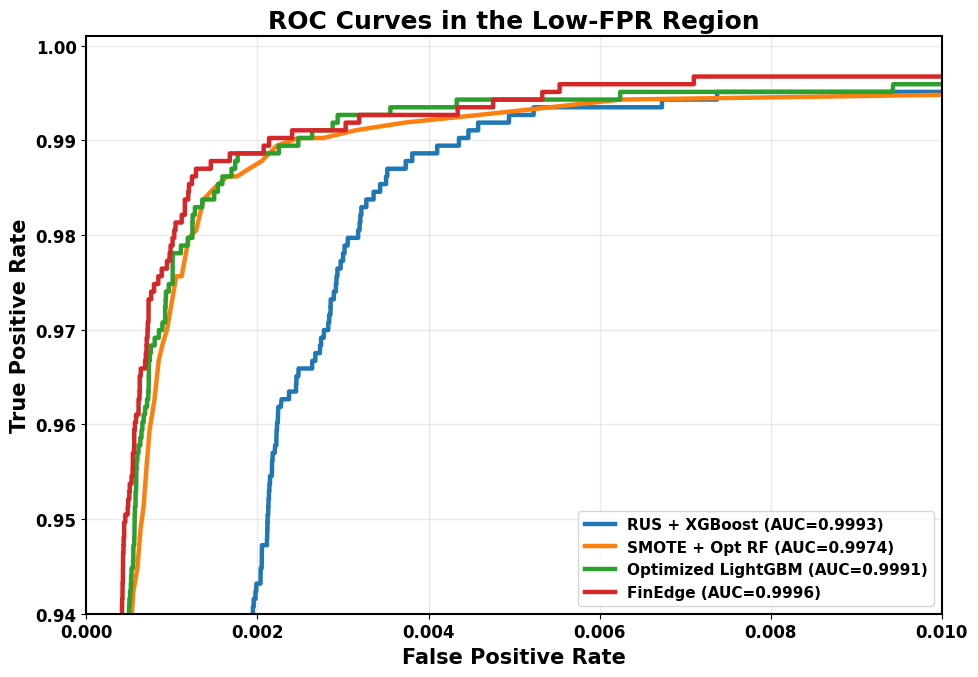

In [2]:
# ================================================================
# ROC CURVES - ZOOMED LOW-FPR REGION
# ================================================================

fig, ax = plt.subplots(figsize=(10, 7))

for name in models.keys():

    fpr, tpr, _ = roc_curve(
        y_test,
        test_probabilities[name]
    )

    auc_value = roc_auc_score(
        y_test,
        test_probabilities[name]
    )

    ax.plot(
        fpr,
        tpr,
        linewidth=3.2,
        label=f"{name} (AUC={auc_value:.4f})"
    )

# Focus on the practically relevant low-FPR region
ax.set_xlim(0, 0.01)
ax.set_ylim(0.94, 1.001)

ax.set_xlabel(
    "False Positive Rate",
    fontweight="bold"
)

ax.set_ylabel(
    "True Positive Rate",
    fontweight="bold"
)

ax.set_title(
    "ROC Curves in the Low-FPR Region",
    fontweight="bold"
)

ax.grid(
    alpha=0.25,
    linewidth=1
)

for tick in ax.get_xticklabels() + ax.get_yticklabels():
    tick.set_fontweight("bold")

legend = ax.legend(
    loc="lower right",
    frameon=True
)

for text in legend.get_texts():
    text.set_fontweight("bold")

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "roc_curves_low_fpr.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

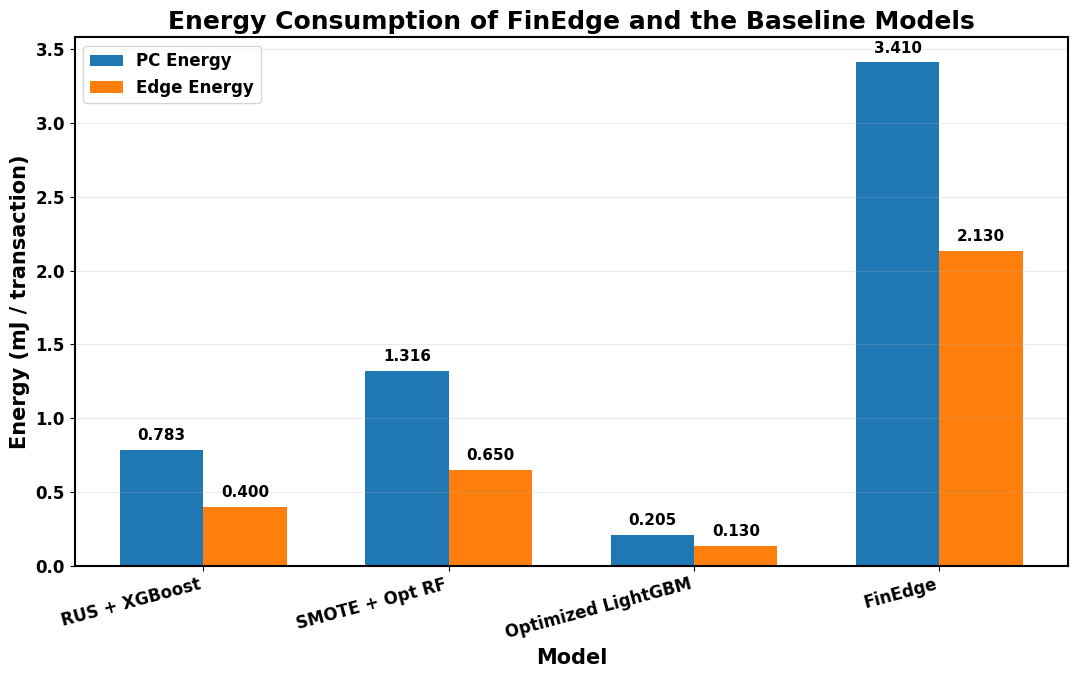

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ================================================================
# GLOBAL STYLE
# ================================================================
plt.rcParams.update({
    "font.size": 14,
    "font.weight": "bold",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "axes.titlesize": 18,
    "axes.labelsize": 15,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "figure.titlesize": 18,
    "axes.linewidth": 1.5,
    "savefig.dpi": 300
})

# ================================================================
# DATA
# ================================================================
models = [
    "RUS + XGBoost",
    "SMOTE + Opt RF",
    "Optimized LightGBM",
    "FinEdge"
]

pc_energy = [0.783, 1.316, 0.205, 3.410]
edge_energy = [0.400, 0.650, 0.130, 2.130]

# ================================================================
# PLOT
# ================================================================
x = np.arange(len(models))
width = 0.34

fig, ax = plt.subplots(figsize=(11, 7))

bars1 = ax.bar(
    x - width/2,
    pc_energy,
    width,
    label="PC Energy"
)

bars2 = ax.bar(
    x + width/2,
    edge_energy,
    width,
    label="Edge Energy"
)

# Labels and title
ax.set_title(
    "Energy Consumption of FinEdge and the Baseline Models",
    fontweight="bold"
)

ax.set_xlabel(
    "Model",
    fontweight="bold"
)

ax.set_ylabel(
    "Energy (mJ / transaction)",
    fontweight="bold"
)

ax.set_xticks(x)
ax.set_xticklabels(models, rotation=15, ha="right", fontweight="bold")

# Bold y ticks
for tick in ax.get_yticklabels():
    tick.set_fontweight("bold")

# Grid
ax.grid(axis="y", alpha=0.25)

# Legend
legend = ax.legend(frameon=True, loc="upper left")
for text in legend.get_texts():
    text.set_fontweight("bold")

# Value labels
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            f"{height:.3f}",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=11,
            fontweight="bold"
        )

plt.tight_layout()

# Save
plt.savefig(
    "energy_consumption_pc_edge.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Revısıon I

# ============================================================
# FinEdge - FEATURE ABLATION EXPERIMENT
# Reviewer 1-C3 / Reviewer 2-C2 / Reviewer 3-C1
# ============================================================

import os
import gc
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna

from IPython.display import display

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    average_precision_score, precision_recall_curve,
    confusion_matrix
)

from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ============================================================
# 1. SETTINGS
# ============================================================

SEED = 42

DATA_PATH = "paysim dataset.csv"
OUTPUT_DIR = "finedge_feature_ablation_results"

os.makedirs(OUTPUT_DIR, exist_ok=True)

N_LGBM_TRIALS = 30
LGBM_TUNING_SIZE = 500_000
RF_TUNING_NORMAL = 500_000

# ============================================================
# 2. LOAD DATASET
# ============================================================

print("Loading PaySim dataset...")

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("Fraud transactions:", df["isFraud"].sum())

# ============================================================
# 3. FEATURE CONFIGURATIONS
# ============================================================

FEATURE_CONFIGS = {

    "Original": [
        "type",
        "amount",
        "oldbalanceOrg",
        "newbalanceOrig",
        "oldbalanceDest",
        "newbalanceDest"
    ],

    "Pre-transaction": [
        "type",
        "amount",
        "oldbalanceOrg",
        "oldbalanceDest"
    ],

    "Balance-free": [
        "type",
        "amount"
    ]
}

# ============================================================
# 4. COMMON DATA SPLIT
# ============================================================

# Generate row indices ONCE.
# All feature configurations use exactly the same observations.

y_all = df["isFraud"].astype(np.uint8)

indices = np.arange(len(df))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    stratify=y_all,
    random_state=SEED
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    stratify=y_all.iloc[temp_idx],
    random_state=SEED
)

meta_idx, threshold_idx = train_test_split(
    val_idx,
    test_size=0.50,
    stratify=y_all.iloc[val_idx],
    random_state=SEED
)

print("\nDATA PARTITIONS")
print("Train:", len(train_idx))
print("Meta:", len(meta_idx))
print("Threshold:", len(threshold_idx))
print("Test:", len(test_idx))

# ============================================================
# 5. HELPER FUNCTIONS
# ============================================================

def find_best_threshold(y_true, probabilities):

    precision, recall, thresholds = precision_recall_curve(
        y_true, probabilities
    )

    p = precision[:-1]
    r = recall[:-1]

    f1 = 2 * p * r / (p + r + 1e-15)

    idx = np.nanargmax(f1)

    return float(thresholds[idx])


def evaluate(y_true, probabilities, threshold):

    predictions = (
        probabilities >= threshold
    ).astype(np.uint8)

    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    return {

        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),

        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),

        "F1": f1_score(
            y_true, predictions, zero_division=0
        ),

        "PR_AUC": average_precision_score(
            y_true, probabilities
        ),

        "Threshold": threshold,

        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn
    }


def make_tuning_subset(X, y, normal_limit, seed):

    # Keep all minority-class observations.
    # Limit majority-class observations for RF tuning.

    rng = np.random.RandomState(seed)

    fraud_positions = np.flatnonzero(
        np.asarray(y) == 1
    )

    normal_positions = np.flatnonzero(
        np.asarray(y) == 0
    )

    selected_normal = rng.choice(
        normal_positions,
        size=min(normal_limit, len(normal_positions)),
        replace=False
    )

    selected = np.concatenate([
        fraud_positions,
        selected_normal
    ])

    rng.shuffle(selected)

    return X.iloc[selected], y.iloc[selected]


# ============================================================
# 6. EXPERIMENT LOOP
# ============================================================

ALL_RESULTS = []

for config_name, features in FEATURE_CONFIGS.items():

    print("\n" + "=" * 75)
    print("RUNNING FEATURE CONFIGURATION:", config_name)
    print("=" * 75)

    # --------------------------------------------------------
    # PREPROCESSING
    # --------------------------------------------------------

    X = df[features].copy()

    X = pd.get_dummies(
        X,
        columns=["type"],
        prefix="type",
        dtype=np.uint8
    )

    X_train = X.iloc[train_idx].copy()
    X_meta = X.iloc[meta_idx].copy()
    X_thr = X.iloc[threshold_idx].copy()
    X_test = X.iloc[test_idx].copy()

    y_train = y_all.iloc[train_idx].copy()
    y_meta = y_all.iloc[meta_idx].copy()
    y_thr = y_all.iloc[threshold_idx].copy()
    y_test = y_all.iloc[test_idx].copy()

    print("Feature count:", X.shape[1])
    print("Features:", list(X.columns))

    # ========================================================
    # 7. BASELINE 1: RUS + XGBOOST
    # ========================================================

    print("\nTraining RUS + XGBoost...")

    xgb_pipeline = Pipeline([

        ("rus", RandomUnderSampler(
            random_state=SEED
        )),

        ("model", XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            booster="gbtree",
            n_estimators=100,
            learning_rate=0.30,
            gamma=0,
            reg_lambda=1,
            reg_alpha=0,
            subsample=1.0,
            random_state=SEED,
            n_jobs=-1
        ))
    ])

    xgb_grid = {

        "rus__sampling_strategy": [
            0.50, 0.75, 1.00
        ],

        "model__max_depth": [
            3, 6, 9
        ]
    }

    xgb_search = GridSearchCV(
        xgb_pipeline,
        xgb_grid,
        scoring="f1",
        cv=StratifiedKFold(
            n_splits=5,
            shuffle=True,
            random_state=SEED
        ),
        n_jobs=-1,
        verbose=0
    )

    xgb_search.fit(X_train, y_train)

    model_xgb = xgb_search.best_estimator_

    print("XGBoost best parameters:")
    print(xgb_search.best_params_)

    # ========================================================
    # 8. BASELINE 2: SMOTE + RANDOM FOREST
    # ========================================================

    print("\nTraining SMOTE + Optimized RF...")

    X_rf_tune, y_rf_tune = make_tuning_subset(
        X_train,
        y_train,
        RF_TUNING_NORMAL,
        SEED
    )

    rf_pipeline = Pipeline([

        ("smote", SMOTE(
            sampling_strategy=1.0,
            k_neighbors=5,
            random_state=SEED
        )),

        ("model", RandomForestClassifier(
            min_samples_split=2,
            max_features="sqrt",
            class_weight="balanced",
            random_state=SEED,
            n_jobs=1
        ))
    ])

    rf_grid = {

        "model__n_estimators": [50, 100],

        "model__max_depth": [None, 10],

        "model__min_samples_leaf": [1, 2]
    }

    rf_search = GridSearchCV(
        rf_pipeline,
        rf_grid,
        scoring="f1",
        cv=StratifiedKFold(
            n_splits=3,
            shuffle=True,
            random_state=SEED
        ),
        n_jobs=-1,
        verbose=0
    )

    rf_search.fit(X_rf_tune, y_rf_tune)

    best_rf_params = rf_search.best_params_

    print("RF best parameters:")
    print(best_rf_params)

    # Full training using selected hyperparameters

    smote = SMOTE(
        sampling_strategy=1.0,
        k_neighbors=5,
        random_state=SEED
    )

    X_smote, y_smote = smote.fit_resample(
        X_train, y_train
    )

    model_rf = RandomForestClassifier(

        n_estimators=best_rf_params[
            "model__n_estimators"
        ],

        max_depth=best_rf_params[
            "model__max_depth"
        ],

        min_samples_leaf=best_rf_params[
            "model__min_samples_leaf"
        ],

        min_samples_split=2,
        max_features="sqrt",
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1
    )

    model_rf.fit(X_smote, y_smote)

    del X_smote, y_smote
    del X_rf_tune, y_rf_tune, rf_search

    gc.collect()

    # ========================================================
    # 9. BASELINE 3: OPTIMIZED LIGHTGBM
    # ========================================================

    print("\nTraining Optimized LightGBM...")

    X_lgb_tune, _, y_lgb_tune, _ = train_test_split(
        X_train,
        y_train,
        train_size=min(
            LGBM_TUNING_SIZE,
            len(X_train)
        ),
        stratify=y_train,
        random_state=SEED
    )

    X_lgb_fit, X_lgb_val, y_lgb_fit, y_lgb_val = (
        train_test_split(
            X_lgb_tune,
            y_lgb_tune,
            test_size=0.20,
            stratify=y_lgb_tune,
            random_state=SEED
        )
    )

    def lgb_objective(trial):

        params = {

            "objective": "binary",

            "n_estimators": 500,

            "num_leaves": trial.suggest_int(
                "num_leaves", 15, 127
            ),

            "max_depth": trial.suggest_int(
                "max_depth", 3, 12
            ),

            "learning_rate": trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            "random_state": SEED,
            "n_jobs": -1,
            "verbosity": -1
        }

        model = LGBMClassifier(**params)

        model.fit(X_lgb_fit, y_lgb_fit)

        prob = model.predict_proba(
            X_lgb_val
        )[:, 1]

        return average_precision_score(
            y_lgb_val, prob
        )

    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=SEED
        )
    )

    study.optimize(
        lgb_objective,
        n_trials=N_LGBM_TRIALS
    )

    model_lgbm = LGBMClassifier(

        objective="binary",
        n_estimators=500,

        num_leaves=study.best_params[
            "num_leaves"
        ],

        max_depth=study.best_params[
            "max_depth"
        ],

        learning_rate=study.best_params[
            "learning_rate"
        ],

        random_state=SEED,
        n_jobs=-1,
        verbosity=-1
    )

    model_lgbm.fit(X_train, y_train)

    print("LightGBM best parameters:")
    print(study.best_params)

    del X_lgb_tune, y_lgb_tune
    del X_lgb_fit, X_lgb_val, y_lgb_fit, y_lgb_val

    gc.collect()

    # ========================================================
    # 10. FINEDGE STACKING
    # ========================================================

    print("\nTraining FinEdge meta-classifier...")

    # Meta-learning uses its own independent validation set.

    meta_rf = model_rf.predict_proba(
        X_meta
    )[:, 1]

    meta_xgb = model_xgb.predict_proba(
        X_meta
    )[:, 1]

    meta_lgbm = model_lgbm.predict_proba(
        X_meta
    )[:, 1]

    Z_meta = np.column_stack([
        meta_rf,
        meta_xgb,
        meta_lgbm
    ])

    meta_classifier = LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=SEED
    )

    meta_classifier.fit(Z_meta, y_meta)

    # ========================================================
    # 11. INDEPENDENT THRESHOLD OPTIMIZATION
    # ========================================================

    print("Optimizing FinEdge threshold...")

    thr_rf = model_rf.predict_proba(
        X_thr
    )[:, 1]

    thr_xgb = model_xgb.predict_proba(
        X_thr
    )[:, 1]

    thr_lgbm = model_lgbm.predict_proba(
        X_thr
    )[:, 1]

    Z_thr = np.column_stack([
        thr_rf,
        thr_xgb,
        thr_lgbm
    ])

    prob_thr = meta_classifier.predict_proba(
        Z_thr
    )[:, 1]

    best_threshold = find_best_threshold(
        y_thr,
        prob_thr
    )

    print("Best threshold:", best_threshold)

    # ========================================================
    # 12. FINAL TEST EVALUATION
    # ========================================================

    print("Evaluating untouched test set...")

    test_rf = model_rf.predict_proba(
        X_test
    )[:, 1]

    test_xgb = model_xgb.predict_proba(
        X_test
    )[:, 1]

    test_lgbm = model_lgbm.predict_proba(
        X_test
    )[:, 1]

    Z_test = np.column_stack([
        test_rf,
        test_xgb,
        test_lgbm
    ])

    prob_test = meta_classifier.predict_proba(
        Z_test
    )[:, 1]

    result = evaluate(
        y_test,
        prob_test,
        best_threshold
    )

    result["Configuration"] = config_name
    result["Features"] = X.shape[1]

    ALL_RESULTS.append(result)

    print("\nRESULT:", config_name)

    print(
        "Precision:",
        round(result["Precision"], 6)
    )

    print(
        "Recall:",
        round(result["Recall"], 6)
    )

    print(
        "F1:",
        round(result["F1"], 6)
    )

    print(
        "PR-AUC:",
        round(result["PR_AUC"], 6)
    )

    # Save after every configuration

    pd.DataFrame(ALL_RESULTS).to_csv(
        os.path.join(
            OUTPUT_DIR,
            "feature_ablation_results.csv"
        ),
        index=False
    )

    del X, X_train, X_meta, X_thr, X_test
    del y_train, y_meta, y_thr, y_test

    del model_rf, model_xgb, model_lgbm
    del meta_classifier

    gc.collect()

# ============================================================
# 13. FINAL RESULTS TABLE
# ============================================================

results_df = pd.DataFrame(ALL_RESULTS)

results_df = results_df[[

    "Configuration",
    "Features",

    "Precision",
    "Recall",
    "F1",
    "PR_AUC",

    "Threshold",

    "TP",
    "FP",
    "FN",
    "TN"
]]

print("\n" + "=" * 75)
print("FINAL FINEDGE FEATURE ABLATION RESULTS")
print("=" * 75)

display(results_df.round(6))

results_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "feature_ablation_results.csv"
    ),
    index=False
)

# ============================================================
# 14. COMPARISON GRAPH - 300 DPI
# ============================================================

plot_df = results_df.set_index(
    "Configuration"
)[[
    "Precision",
    "Recall",
    "F1",
    "PR_AUC"
]]

ax = plot_df.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.75,
    rot=0
)

ax.set_title(
    "FinEdge Feature Ablation Analysis",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_ylabel("Score", fontsize=13)
ax.set_xlabel("Feature Configuration", fontsize=13)

ax.set_ylim(0, 1.05)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

ax.legend(
    loc="lower left",
    ncol=2,
    fontsize=10
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "feature_ablation_300dpi.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nEXPERIMENT COMPLETED.")
print("Results saved to:", OUTPUT_DIR)

Loading PaySim dataset...
Dataset shape: (6362620, 11)
Fraud transactions: 8213

DATA PARTITIONS
Train: 4453834
Meta: 477196
Threshold: 477197
Test: 954393

RUNNING FEATURE CONFIGURATION: Original
Feature count: 10
Features: ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']

Training RUS + XGBoost...
XGBoost best parameters:
{'model__max_depth': 9, 'rus__sampling_strategy': 0.5}

Training SMOTE + Optimized RF...


In [4]:
!pip install lightgbm

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   --------------- ------------------------ 0.5/1.4 MB 4.6 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 6.3 MB/s eta 0:00:00
